In [ ]:
import numpy as np

data=np.load('/content/drive/MyDrive/Colab Notebooks/data.npy')
target=np.load('/content/drive/MyDrive/Colab Notebooks/target.npy')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:

print("Data shape:", data.shape)
print("Target shape:", target.shape)
print("First 5 targets:", target[:5])

Data shape: (24997, 50, 50, 1)
Target shape: (24997, 2)
First 5 targets: [[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [20]:
print(data.shape[1:])

(50, 50, 1)


In [21]:

from keras.models import Sequential
from keras.layers import Conv2D,MaxPooling2D,Dense,Flatten,Activation,Dropout,BatchNormalization

model=Sequential()

#model.add(Conv2D(256,(3,3),input_shape=(50,50,1))) l=256
model.add(Conv2D(256,(3,3),input_shape=data.shape[1:],padding='same',kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(128,(3,3),kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(64,(3,3),kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dropout(0.5))
model.add(Dense(200,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(100,activation='relu'))
model.add(Dense(50,activation='relu'))
model.add(Dense(2,activation='softmax'))

model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 256)    │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 23, 23, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 23, 23, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 9, 9, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 200)            │       205,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 603,436 (2.30 MB)

 Trainable params: 602,540 (2.30 MB)

 Non-trainable params: 896 (3.50 KB)

In [22]:
from sklearn.model_selection import train_test_split

train_data,test_data,train_target,test_target=train_test_split(data,target,test_size=0.1)

In [23]:
#from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

aug = ImageDataGenerator(rotation_range=20,zoom_range=0.15,width_shift_range=0.2,height_shift_range=0.2,shear_range=0.15,
                         horizontal_flip=True,fill_mode="nearest")

In [24]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/Colab Notebooks/models/model-{epoch:03d}.weights.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True,
    mode='min',
    verbose=1
)

#early_stop = EarlyStopping(
    #monitor='val_loss',
    #patience=4,
    #restore_best_weights=True
#)

In [26]:
#history = model.fit(data,target,epochs=20,validation_split=0.2,batch_size=32)
#history=model.fit(aug.flow(train_data,train_target,batch_size=bs),steps_per_epoch=len(train_data)//bs,validation_data=(test_data,test_target),validation_steps=len(test_data)//bs,epochs=20)
bs = 32

history = model.fit(
    aug.flow(train_data, train_target, batch_size=bs),
    epochs=20,
    steps_per_epoch=int(np.ceil(len(train_data) / bs)),
    validation_data=(test_data, test_target),
    callbacks=[checkpoint]
)

Epoch 1/20
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5790 - loss: 0.6796
Epoch 1: val_loss did not improve from 1.18576
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.5994 - loss: 0.6656 - val_accuracy: 0.4760 - val_loss: 3.1821
Epoch 2/20
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6463 - loss: 0.6327
Epoch 2: val_loss did not improve from 1.18576
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.6545 - loss: 0.6250 - val_accuracy: 0.4760 - val_loss: 3.7573
Epoch 3/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6839 - loss: 0.5985
Epoch 3: val_loss did not improve from 1.18576
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.6917 - loss: 0.5920 - val_accuracy: 0.4760 - val_loss: 3.4747
Epoch 4/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7055 - loss: 0.5714
Epoch 4: val_loss did not improve from 1.18576
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.7113 - loss: 0.5639 - val_accuracy: 0.4760 - val_l

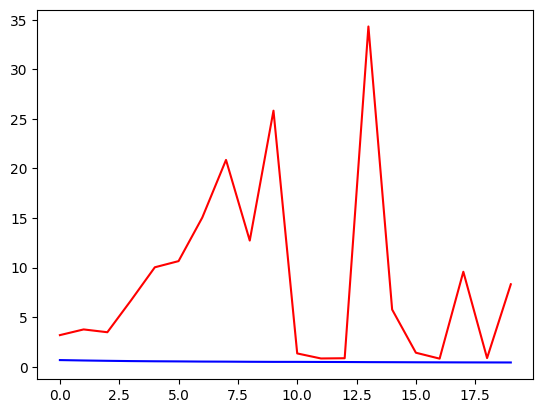

In [27]:
from matplotlib import pyplot as plt

plt.plot(history.history['loss'],'b')
plt.plot(history.history['val_loss'],'r')

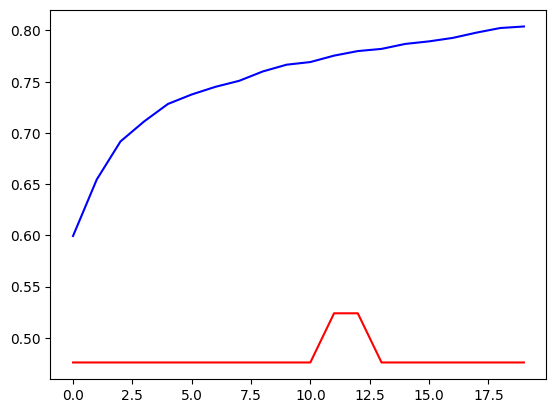

In [28]:
plt.plot(history.history['accuracy'],'b')
plt.plot(history.history['val_accuracy'],'r')

In [32]:
import os
model_path = '/content/drive/MyDrive/Colab Notebooks/models'

files = [
    f for f in os.listdir(model_path)
    if f.endswith('.weights.h5')
]

for f in files:
    print(f)

model-001.weights.h5
model-012.weights.h5
model-017.weights.h5


In [33]:
import numpy as np

results = []

for f in files:
    model.load_weights(os.path.join(model_path, f))

    loss, accuracy = model.evaluate(
        test_data, test_target, verbose=0
    )

    results.append((f, loss, accuracy))

for f, loss, accuracy in sorted(results, key=lambda x: x[1]):
    print(f'{f}: Loss={loss:.4f}, Accuracy={accuracy:.4f}')

model-017.weights.h5: Loss=0.8108, Accuracy=0.4760
model-012.weights.h5: Loss=0.8284, Accuracy=0.5240
model-001.weights.h5: Loss=1.1858, Accuracy=0.5240


In [ ]:
#model.save('/content/drive/MyDrive/Colab Notebooks/cat-dog-model-new.keras')